<a href="https://colab.research.google.com/github/AlexBecerril/miaad-sem1/blob/main/Actividad_EDA_predictivo_bank_marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Edgar Alejandro Becerril Caballero  

**Matrícula:** 275333

**Fecha:** 09/10/2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [ ]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
VIOLETA = "#6C3BCE"
LIMA = "#B8D833"
COLORES_CLASE = {"no": VIOLETA, "yes": LIMA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | Un contacto telefónico |
| ¿Qué se predice? | Si el cliente contratara el deposito a plazo |
| ¿Qué tipo de problema es? | Clasificación binaria |
| ¿En qué momento se haría la predicción y qué información existiría entonces? | La predicción se haría antes de realizar la llamada, existiría la información del cliente y de la campaña hasta ese momento |
| ¿Qué columnas no deberían usarse como características y por qué? | duration no debería utilizarse porque representa la duración de la llamada actual y solo se conoce después de realizarla |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Considero que una tasa de conversión de al rededor del 20% sería un valor esperado.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Creo que si existiran valores faltantes, especialmente en las columnas que contienen datos personales como job, marital y education, si tuviera que hacer una estimación diría que al rededor del 30% de las filas podrian contener valores nulos o faltantes en dichas columnas.

In [ ]:
# B1. Estructura. Escribe el código que muestre:

In [ ]:
df.head(10)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,198,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,139,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,217,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,380,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,50,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
#  - las dimensiones del conjunto,
#  - el tipo de dato de cada columna,
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [ ]:
#  - el número de valores únicos por columna, de menor a mayor.
df.nunique().sort_values()

,0
contact,2
y,2
default,3
loan,3
poutcome,3
housing,3
marital,4
day_of_week,5
previous,8
education,8


In [ ]:
# Detección de columnas categoricas
columnas_categoricas = df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

for x in columnas_categoricas:
  print(x)
  print(df[x].value_counts().sort_index())
  print()



job
job
admin.           10422
blue-collar       9254
entrepreneur      1456
housemaid         1060
management        2924
retired           1720
self-employed     1421
services          3969
student            875
technician        6743
unemployed        1014
unknown            330
Name: count, dtype: int64

marital
marital
divorced     4612
married     24928
single      11568
unknown        80
Name: count, dtype: int64

education
education
basic.4y                4176
basic.6y                2292
basic.9y                6045
high.school             9515
illiterate                18
professional.course     5243
university.degree      12168
unknown                 1731
Name: count, dtype: int64

default
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

housing
housing
no         18622
unknown      990
yes        21576
Name: count, dtype: int64

loan
loan
no         33950
unknown      990
yes         6248
Name: count, dtype: int64

contact
contact
cel

In [ ]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
#  - ese conteo como porcentaje de las filas.

# Visualización de las columnas detectadas
for x in columnas_categoricas:
  unknown = (df[x] == 'unknown').sum()
  if unknown > 0:
    print('Columna:',x)
    print('Valores desconocidos:',unknown)
    print('Porcentaje de desconocidos:', round((unknown / len(df)) * 100,2),'%\n')

Columna: job
Valores desconocidos: 330
Porcentaje de desconocidos: 0.8 %

Columna: marital
Valores desconocidos: 80
Porcentaje de desconocidos: 0.19 %

Columna: education
Valores desconocidos: 1731
Porcentaje de desconocidos: 4.2 %

Columna: default
Valores desconocidos: 8597
Porcentaje de desconocidos: 20.87 %

Columna: housing
Valores desconocidos: 990
Porcentaje de desconocidos: 2.4 %

Columna: loan
Valores desconocidos: 990
Porcentaje de desconocidos: 2.4 %



In [ ]:
#  - el total de valores NaN del conjunto,
print("Valores faltantes (NaN) en todo el conjunto:", df.isna().sum().sum())

Valores faltantes (NaN) en todo el conjunto: 0


In [ ]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 12


In [ ]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
pdays999 = (df["pdays"] == 999).sum()
print('Filas con pdays igual a 999:',pdays999)
print('Porcentaje:', round((pdays999 / len(df)) * 100,2),'%\n')

Filas con pdays igual a 999: 39673
Porcentaje: 96.32 %



In [ ]:
#  - una tabla de contingencia entre poutcome y (previous == 0),
tabla1 = pd.crosstab(
    df['poutcome'],
    df['previous'] == 0,
    normalize='index'
) * 100

tabla1 = tabla1.round(2)
tabla1

previous,False,True
poutcome,,
failure,100.0,0.0
nonexistent,0.0,100.0
success,100.0,0.0


In [ ]:
#  - una tabla de contingencia entre poutcome y (pdays == 999).
tabla2 = pd.crosstab(
    df['poutcome'],
    df['pdays'] == 999,
    normalize='index'
) * 100

tabla2 = tabla2.round(2)
tabla2

pdays,False,True
poutcome,,
failure,3.34,96.66
nonexistent,0.00,100.00
success,100.00,0.00


In [ ]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
print("Edad mínima:", df["age"].min())
print("Edad máxima:", df["age"].max())
#  - cuántas llamadas tienen duration igual a 0,
print("Filas con duration igual a 0:", len(df[df["duration"] == 0]))
#  - el mínimo y el máximo de campaign,
print("Campaign mínimo:", df["campaign"].min())
print("Campaign máximo:", df["campaign"].max())
#  - cuántas filas tienen previous negativo.
print("Filas con previous negativo:", len(df[df["previous"] < 0]))

Edad mínima: 17
Edad máxima: 98
Filas con duration igual a 0: 4
Campaign mínimo: 1
Campaign máximo: 56
Filas con previous negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable. Escribe tu respuesta aquí y compárala con tu predicción.

* La convensión de nombres de las columnas son inconsistentes, existen columnas como emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m y nr.employed que podrían ser modificadas para alinearse con el formato (snake case) de las demás y facilitar su lectura.
* Los valores en columnas como job y education contienen valores que tienen puntos y guiones, aunque dichos valores se encuentran representados en formatos dificiles de leer, no encontre duplicidad.
* La columna default contiene un 21% de valores con "unknown", unicamente 3 valores "yes" y el resto de valores "no".
* Para las demás columnas categoricas el porcentaje de "unknown" esta por debajo del 5% y no se encontraron valores NaN en las columnas númericas.
* Existen 12 filas duplicadas pero al no contar con un identificador unico para los contactos o un número de telefono, se pudiera tratar de coincidencias.
* El 96.32 % de los registros tiene pdays = 999, código que indica que el cliente no había sido contactado previamente en una campaña anterior.



**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado. Escribe tu respuesta aquí.

**Respuesta:** Mantendría unknown inicialmente como una categoría explícita, ya que presenta una tasa de contratación diferente a no (5.2 % frente a 12.9 %). No imputaría unknown como yes o no porque no conocemos su significado real. La categoría yes debe tratarse con cautela porque solamente contiene 3 registros.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** La proporción debería mantenerse, ya que estaremos utilizando explicitamente statratify=df[\"y\"] al dividir el conjunto de datos, precisamente para mantener aproximadamente la misma proporción de clases y no afectar los procesos de entrenamiento y prueba del modelo.

In [ ]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
entrenamiento, prueba = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=42)
ent = entrenamiento.copy()
ent["suscribe"] = ent["y"].apply(lambda x: 1 if x == "yes" else 0)

# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
print("Entrenamiento:", entrenamiento.shape, "| Prueba:", prueba.shape)
#  - el porcentaje de contratación (y igual a yes) en cada uno.
print("Contratación en entrenamiento:", round((entrenamiento["y"] == "yes").mean() * 100, 1), "%")
print("Contratación en prueba:", round((prueba["y"] == "yes").mean() * 100, 1), "%")

Entrenamiento: (32950, 21) | Prueba: (8238, 21)
Contratación en entrenamiento: 11.3 %
Contratación en prueba: 11.3 %


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [ ]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:** la proporción de contratación se mantuvo en 11.3 % tanto en entrenamiento como en prueba, como se esperaba debido a la división estratificada.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Tendría una exactitud del 88.7% ya que tanto en el conjunto de entrenamiento como en el de prueba la variable objetivo arroja "si" en un 11.3% de las veces


     clientes  porcentaje
y                        
no      29238        88.7
yes      3712        11.3

Razón entre clases (mayoritaria / minoritaria): 7.88
Exactitud de responder siempre No: 88.7 %


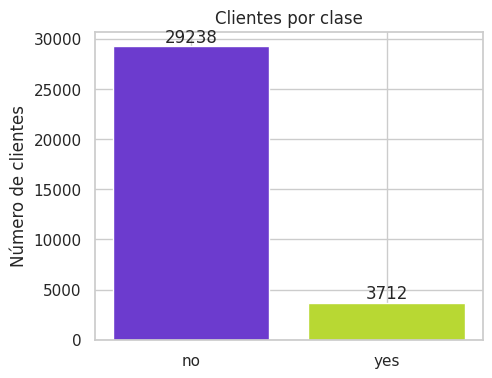

In [ ]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
conteo = ent["y"].value_counts()
porcentaje = (ent["y"].value_counts(normalize=True) * 100).round(1)
print(pd.DataFrame({"clientes": conteo, "porcentaje": porcentaje}))
print()
#  - la razón entre la clase mayoritaria y la minoritaria,
print("Razón entre clases (mayoritaria / minoritaria):", round(conteo["no"] / conteo["yes"], 2))
#  - la exactitud de responder siempre "no",
print("Exactitud de responder siempre No:", round((1 - ent["suscribe"].mean()) * 100, 1), "%")

#  - una gráfica de barras con el número de clientes por clase.
fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(conteo.index, conteo.values, color=conteo.index.map(COLORES_CLASE))
ax.bar_label(barras)
ax.set_title("Clientes por clase")
ax.set_ylabel("Número de clientes")
plt.show()

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuestas:** La variable objetivo presenta un desbalance considerable: 88.7 % de los contactos no contrataron y 11.3 % sí contrataron. Un modelo que siempre predijera no tendría una exactitud de 88.7 %, por lo que la exactitud por sí sola no sería suficiente para evaluar el desempeño. Será necesario considerar métricas como F1 para medir la efectividad real.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Creo que probablemente la edad y la duración de la llamada, creo que las personas que contratan deben de estar en un rango de edad mayor y la duración de las llamadas de rechazo debería ser mucho menor a las de contratación.

In [ ]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
numericas = ent.select_dtypes(
    include=['int64']
).columns.tolist()

numericas.remove("suscribe")

print(ent.groupby("y")[numericas].median().round(2))

      age  duration  campaign  pdays  previous
y                                             
no   38.0     164.0       2.0  999.0       0.0
yes  37.0     448.0       2.0  999.0       0.0


count    32950.000000
mean        40.014112
std         10.403636
min         17.000000
25%         32.000000
50%         38.000000
75%         47.000000
max         98.000000
Name: age, dtype: float64
count    32950.000000
mean       258.127466
std        258.975917
min          0.000000
25%        103.000000
50%        180.000000
75%        319.000000
max       4918.000000
Name: duration, dtype: float64
count    32950.000000
mean         2.560607
std          2.752326
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         56.000000
Name: campaign, dtype: float64
count    32950.000000
mean       962.052413
std        187.951096
min          0.000000
25%        999.000000
50%        999.000000
75%        999.000000
max        999.000000
Name: pdays, dtype: float64
count    32950.000000
mean         0.174719
std          0.499025
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          7.000000
Name

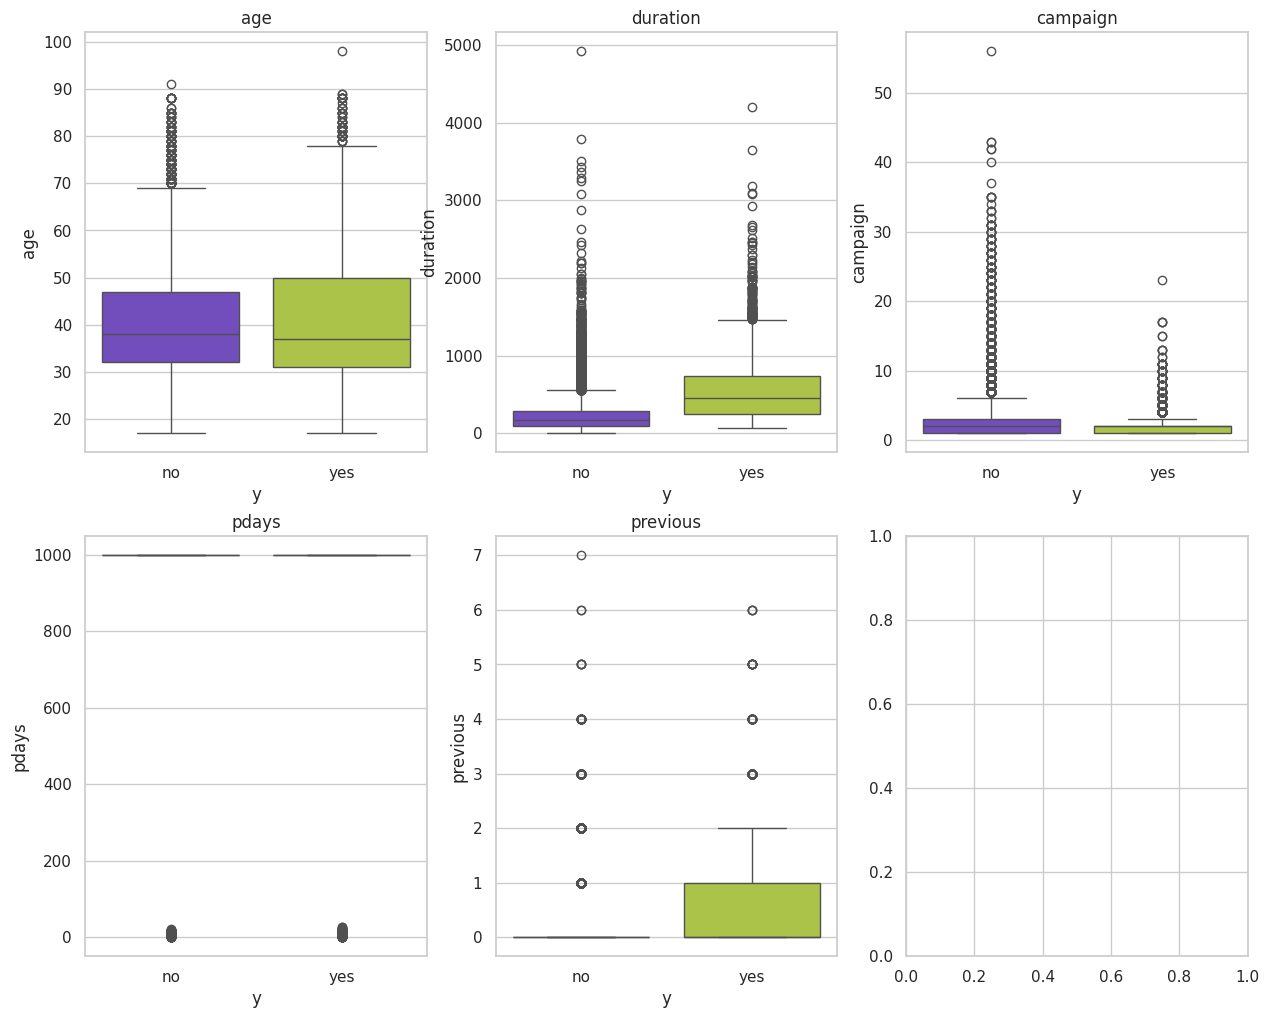

In [ ]:
#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.
fig, ejes = plt.subplots(2, 3, figsize=(15, 12))

ejes = ejes.flatten()

for index, x in enumerate(numericas):
  sns.boxplot(data=ent, x="y", y=x, hue="y", order=["no", "yes"], palette=COLORES_CLASE, legend=False, ax=ejes[index])
  ejes[index].set_title(x)
  print(ent[x].describe())

plt.show()

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:** La variable que presenta la mayor diferencia entre las clases es duration, con una mediana de 448 segundos para las contrataciones frente a 164 para los rechazos. age presenta una diferencia pequeña, de 37 a 38 años, mientras que campaign, pdays y previous tienen la misma mediana en ambas clases.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Creo que la variable "duration" será la que presentara más registros fuera ya que es la que tiene mayor cardinalidad y por lo tanto más dispersión en sus valores, otras que pudieran presentar valores fuera pudieran ser también "age" y "campaign"

In [ ]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.

q1 = ent[numericas].quantile(0.25)
q3 = ent[numericas].quantile(0.75)
ric = q3 - q1
inferior = q1 - 1.5 * ric
superior = q3 + 1.5 * ric

print("Registros fuera de los límites de Tukey (1.5 RIC), por variable:")
print(((ent[numericas] < inferior) | (ent[numericas] > superior)).sum())


Registros fuera de los límites de Tukey (1.5 RIC), por variable:
age          368
duration    2366
campaign    1916
pdays       1226
previous    4534
dtype: int64


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado. Escribe tu respuesta aquí.

**Respuesta:** No eliminaría automáticamente los valores identificados como atípicos. En duration, los valores altos pueden representar llamadas reales, por lo que sería preferible conservarlos y, para modelos sensibles a escala, considerar una transformación. En campaign, el máximo de 56 contactos también puede ser válido, por lo que no lo eliminaría únicamente por el criterio de Tukey. En pdays, el valor 999 no debe tratarse como un outlier convencional porque representa un código especial.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Tipicamente el logaritmo tiende a reducir de manera más drastica la asimetía positiva.

In [ ]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.

for x in numericas:
  comparacion = pd.DataFrame({
    "original": [ent[x].skew()],
    "raiz_cuadrada": [np.sqrt(ent[x]).skew()],
    "logaritmo": [np.log1p(ent[x]).skew()],
  }, index=[x]).round(2)
  print(comparacion)
  print('\n')

     original  raiz_cuadrada  logaritmo
age      0.76           0.43       0.13


          original  raiz_cuadrada  logaritmo
duration      3.33            1.2      -0.43


          original  raiz_cuadrada  logaritmo
campaign      4.74           2.16       1.35


       original  raiz_cuadrada  logaritmo
pdays     -4.89           -4.9      -4.97


          original  raiz_cuadrada  logaritmo
previous      3.85           2.38       2.58




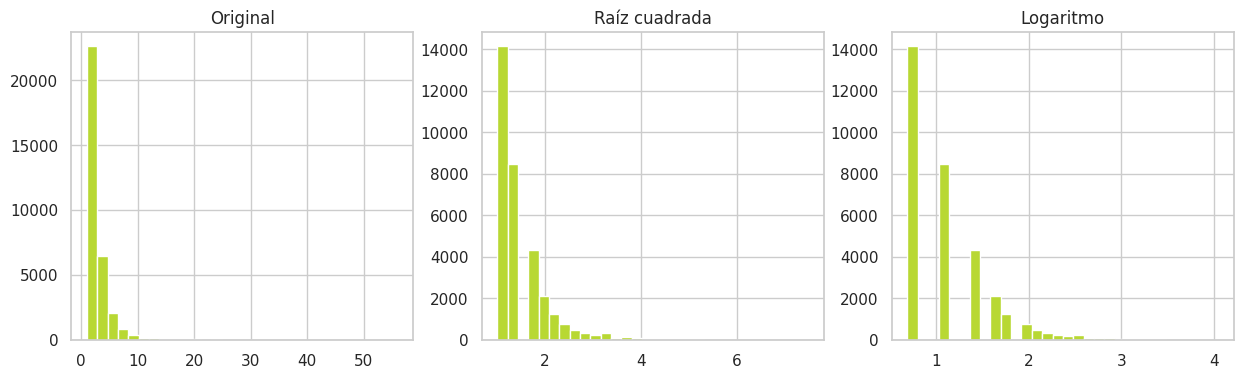

In [ ]:
# Después grafica los histogramas de campaign: original y transformada.
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].hist(ent['campaign'].dropna(), bins=30, color=LIMA, edgecolor="white")
ejes[0].set_title("Original")
ejes[1].hist(np.sqrt(ent['campaign']).dropna(), bins=30, color=LIMA, edgecolor="white")
ejes[1].set_title("Raíz cuadrada")
ejes[2].hist(np.log1p(ent['campaign']).dropna(), bins=30, color=LIMA, edgecolor="white")
ejes[2].set_title("Logaritmo")
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:** age presenta una asimetría moderada de 0.76 y el logaritmo la reduce a 0.13. duration presenta una asimetría fuerte de 3.33 y el logaritmo la reduce a -0.43. campaign pasa de 4.74 a 1.35 con log1p, por lo que también sería la transformación más efectiva. En previous, la raíz cuadrada reduce la asimetría de 3.85 a 2.38, aunque continúa siendo elevada. Estas transformaciones serían especialmente relevantes para modelos sensibles a escala, no necesariamente para modelos basados en árboles.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Yo creo que probablemente variables como job, marital y education podrían separar efectivamente la variable objetivo, ya que, según infiero, pudieran asociarse con caracteristicas de personas que contratan un credito bancario (casadas, con trabajo y educación superior)

In [ ]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
categoricas = ent.select_dtypes(
    include=['object', 'category']
).columns.tolist()

categoricas.remove('y')

print("Número de categorías por característica:")
print(ent[categoricas].nunique().sort_values())
print()
#  - la tasa global de contratación en ent.
print("Tasa de contratación global:", round(ent["suscribe"].mean() * 100, 1), "%")

Número de categorías por característica:
contact         2
default         3
housing         3
loan            3
poutcome        3
marital         4
day_of_week     5
education       8
month          10
job            12
dtype: int64

Tasa de contratación global: 11.3 %


In [ ]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
#  - las 12 categorías con mayor tasa,
#  - las 8 con menor tasa,
#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.

largo = ent[categoricas].astype(str).assign(contratacion=ent["suscribe"]).melt(
    id_vars="contratacion", var_name="caracteristica", value_name="categoria"
)
tasas = largo.groupby(["caracteristica", "categoria"])["contratacion"].agg(clientes="count", tasa_contratacion="mean")
tasas["tasa_contratacion"] = (tasas["tasa_contratacion"] * 100).round(1)

print("Categorías con mayor tasa de contratacion:")
print(tasas.sort_values("tasa_contratacion", ascending=False).head(10))
print()
print("Categorías con menor tasa de contratacion:")
print(tasas.sort_values("tasa_contratacion", ascending=False).tail(8))
print()
print("Tasa de contratacion según default:")
print(tasas.loc["default"])
print()
print("Tasa de contratación según housing:")
print(tasas.loc["housing"])
print()
print("Tasa de contratación según loan:")
print(tasas.loc["loan"])
print()
print("Tasa de contratación según day_of_week:")
print(tasas.loc["day_of_week"])

Categorías con mayor tasa de contratacion:
                           clientes  tasa_contratacion
caracteristica categoria                              
poutcome       success         1105               64.9
month          dec              143               50.3
               mar              436               49.8
               sep              464               44.6
               oct              587               43.3
job            student          711               30.5
               retired         1366               25.5
month          apr             2085               20.5
education      illiterate        16               18.8
marital        unknown           65               16.9

Categorías con menor tasa de contratacion:
                            clientes  tasa_contratacion
caracteristica categoria                               
education      basic.6y         1865                8.4
job            services         3196                7.9
education      basic.9y      

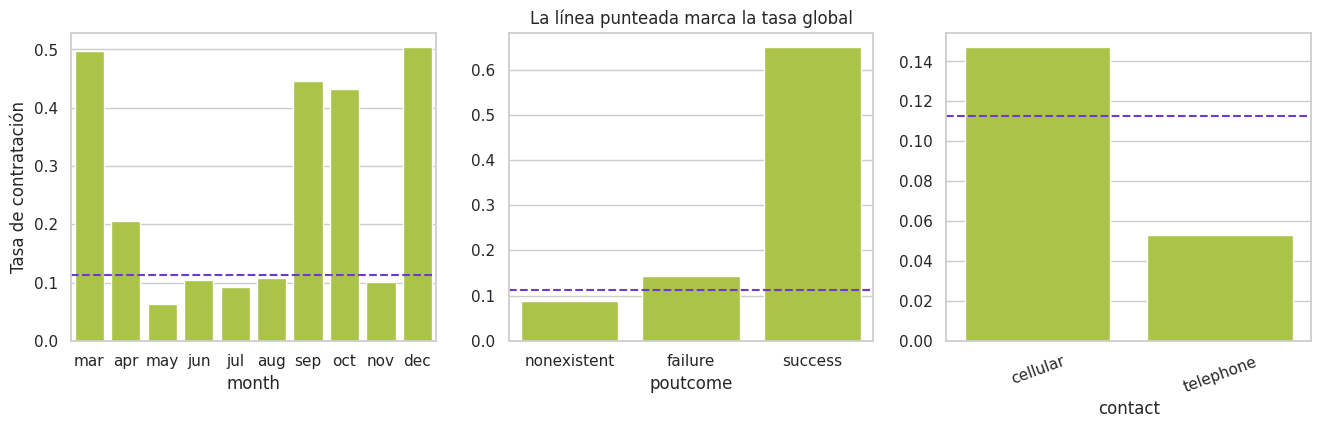

In [ ]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=ent, x="month", y="suscribe", order=["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], color=LIMA, errorbar=None, ax=ejes[0])
sns.barplot(data=ent, x="poutcome", y="suscribe", color=LIMA, errorbar=None, ax=ejes[1])
sns.barplot(data=ent, x="contact", y="suscribe", color=LIMA, errorbar=None, ax=ejes[2])
ejes[2].tick_params(axis="x", rotation=20)
ejes[0].axhline(ent["suscribe"].mean(), color=VIOLETA, linestyle="--")
ejes[1].axhline(ent["suscribe"].mean(), color=VIOLETA, linestyle="--")
ejes[2].axhline(ent["suscribe"].mean(), color=VIOLETA, linestyle="--")
ejes[0].set_ylabel("Tasa de contratación")
ejes[1].set_ylabel("")
ejes[2].set_ylabel("")
ejes[1].set_title("La línea punteada marca la tasa global")
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:**
poutcome = success presenta la mayor tasa de contratación, con 64.9 % en 1,105 clientes. También destacan diciembre (50.3 %), marzo (49.8 %), septiembre (44.6 %) y octubre (43.3 %). En contraste, default = unknown tiene 5.2 % en 6,940 clientes y contact = telephone 5.3 % en 12,042 clientes.

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.
* La columna default indica si el contacto cuenta con un contrato en incumplimiento, los valores "no" tienen una tasa de contratación ligeramente mayor a la global y los valores "si" tienen una tasa de 0, ambas tienen sentido, sin embargo "unknown" tiene una tasa de contratación del 5%, muy por debajo de la tasa global, por lo cual sería complicado imputar estos valores como "yes" o "no".
* la categoria "yes" de default cuenta con unicamente 3 registros y la categoria de "illiterate" de education cuenta con unicamente 16 registros, yo tomaria estos valores con cautela ya que representan una minoria dentro del conjunto de datos, por lo cual no son representativas y pudieran causar alteraciones en el entrenamiento del modelo.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Probablemente el indice de confianza del consumidor y el indice de precios

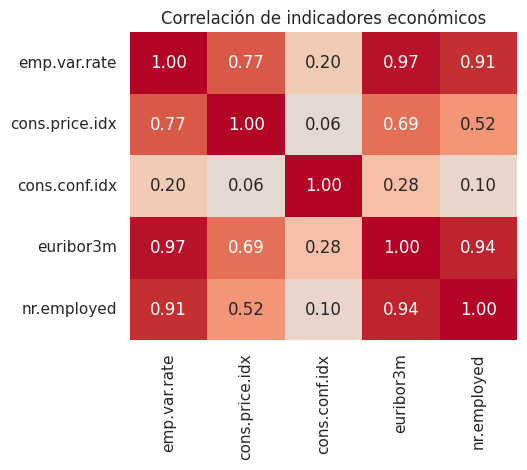

In [ ]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.
#variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(ent[macro].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=False, ax=ax)
ax.set_title("Correlación de indicadores económicos")
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:**
La variación del empleo y la tasa Euribor a 3 meses tienen una correlación del 97%
El número de empleados y la tasa Euribor a 3 meses tienen una correlación del 94%
La variación del empleo y el número de empleados tiene una correlación del 91%
La variación del empleo y el indice de precios tienen una correlación del 77%

curiosamente las que se encuentran menos relacionadas, contrario a la predicción, son precisamente el indice de precios y el indice de confianza del consumidor


### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [ ]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.
ent.groupby("y")["duration"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,29238.0,221.15,208.30,0.0,95.0,164.0,279.0,4918.0
yes,3712.0,549.40,397.49,63.0,252.0,448.0,737.0,4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.

**Respuesta:** No incluiría duration en un modelo utilizado para decidir a quién llamar, porque esta variable corresponde a la duración de la llamada actual y solo se conoce después de que la llamada ha ocurrido.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.

**Respuesta:** Como el conjunto está ordenado temporalmente y los indicadores económicos cambian con el tiempo, para evaluar un modelo destinado a campañas futuras sería preferible una división temporal, utilizando periodos anteriores para entrenamiento y periodos posteriores para evaluación.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

**Resupuesta:**

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
| duration presenta medianas de 164 para no y 448 para yes, pero solo se conoce después de realizar la llamada. | No utilizar duration como característica para decidir a quién llamar. | Modelos |
| default contiene 8,597 registros unknown (20.87 %) y solo 3 registros yes. | Mantener unknown como categoría explícita inicialmente y evaluar su comportamiento. no imputarlo como yes o no. | Preprocesamiento |
| pdays = 999 aparece en 39,673 registros (96.32 %) y representa que el cliente no fue contactado previamente. | Tratar 999 como un código especial y no como un valor numérico convencional. | Preprocesamiento |
| La variable objetivo tiene 88.7 % de no y 11.3 % de yes, con una razón de 7.88 a 1 entre clases. | No utilizar accuracy como única métrica. | Evaluación / Modelos |
| emp.var.rate y euribor3m presentan una correlación de 0.97; euribor3m y nr.employed, 0.94. | Evaluar la eliminación de variables redundantes. | Preprocesamiento / Modelos |
| campaign presenta una asimetría de 4.74, que disminuye a 1.35 con np.log1p. | Considerar la transformación logarítmica para modelos sensibles a escala. | Preprocesamiento |
| duration presenta 2,366 registros fuera de los límites de Tukey, pero sus valores altos pueden representar llamadas reales. | No eliminar automáticamente los valores atípicos, considerar transformaciones en lugar de eliminarlos. | Preprocesamiento |
| default = yes tiene solo 3 registros y education = illiterate tiene 16. | Tratar estas categorías con cautela | Preprocesamiento / Modelos |
| El conjunto está ordenado temporalmente y los indicadores económicos varían con el tiempo. | Para evaluar desempeño en campañas futuras, utilizar una validación o división temporal en lugar de depender únicamente de una división aleatoria. | Evaluación |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

**Respuesta:**

La exploración de la Parte B se realizó sobre el conjunto total (df), ya que corresponde a verificaciones estructurales y de calidad. En la Parte C se realizó la división estratificada en 80 % de entrenamiento y 20 % de prueba.

A partir de la división, las partes D, E y F se realizaron únicamente sobre el conjunto de entrenamiento (ent). Esto permite utilizar la información del entrenamiento para tomar decisiones de preprocesamiento y modelado sin incorporar información del conjunto de prueba.

El conjunto prueba debe conservarse sin explorar hasta la evaluación final del modelo, para obtener una estimación imparcial de su desempeño.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respuesta aquí.

**Respuesta:**

Si también se hubiera explorado el conjunto de prueba, las decisiones podrían quedar sesgadas porque incorporarían información del conjunto utilizado posteriormente para evaluar el modelo.

Por esta razón, las decisiones de preprocesamiento y modelado se basan únicamente en ent, mientras que prueba se reserva para la evaluación final.